In [1]:
import pandas as pd
import numpy as np
from basin import *
from MultiAgent_DQ import *
import sys
sys.path.append('../')
from utils import *

In [2]:
# Parameters
t = 1
s = 0
r = 0.8
p = 0.2
epsilon = 0.1
d = 0.6
alpha = 0.3
bound = 1 / (1 - d)

# CASE BY CASE STUDY

In [3]:
import numpy as np

def trim_q_by_strategy(q1, q2, s1, s2):
    """
    Trim q1 and q2 sequences based on their respective initial strategy orderings.
    Both sequences are cut to the same length, determined by when *either* violates
    its initial ordering — whichever lasts longer determines the trim point.
    
    Parameters
    ----------
    q1, q2 : pd.DataFrame or np.ndarray
        Time × features (Q-values). Must have same length along time axis.
    s1, s2 : str
        Strategies for q1 and q2, each one of {"AD","GT","AGT","AC"}.
        
    Returns
    -------
    q1_trimmed, q2_trimmed : same type as input
        Trimmed sequences up to the last timestep where both maintain initial ordering.
    """
    
    # Convert to numpy if DataFrames
    q1_arr = q1.values if hasattr(q1, "values") else np.asarray(q1)
    q2_arr = q2.values if hasattr(q2, "values") else np.asarray(q2)
    
    def ordering_sign(Q, strategy):
        """
        Compute sign of (defect - coop) according to strategy from a 2x2 Q-matrix or row pair.
        Positive sign → defect > coop, Negative → coop > defect.
        """
        delta = Q[1] - Q[0]
        if strategy in ["GT", "AC"]:
            delta = -delta
        return np.sign(delta)
    
    def valid_length(Q, strategy):
        """Return how long ordering stays consistent with the initial."""
        # Use first two timesteps as reference
        ref_sign = ordering_sign(Q[:2], strategy)
        last_valid_idx = 1
        for t in range(1, Q.shape[0]):
            cur_sign = ordering_sign(Q[t-1:t+1], strategy)
            if np.all(cur_sign == ref_sign):
                last_valid_idx = t
            else:
                break
        return last_valid_idx + 1  # inclusive index
    
    len1 = valid_length(q1_arr, s1)
    len2 = valid_length(q2_arr, s2)
    
    # Cut based on whichever lasts longer
    cut_len = min(len1, len2) 
    
    if hasattr(q1, "iloc"):
        return q1.iloc[:cut_len], q2.iloc[:cut_len]
    else:
        return q1_arr[:cut_len], q2_arr[:cut_len]


Using seed: 327164698
Running pair: (AC, AC)


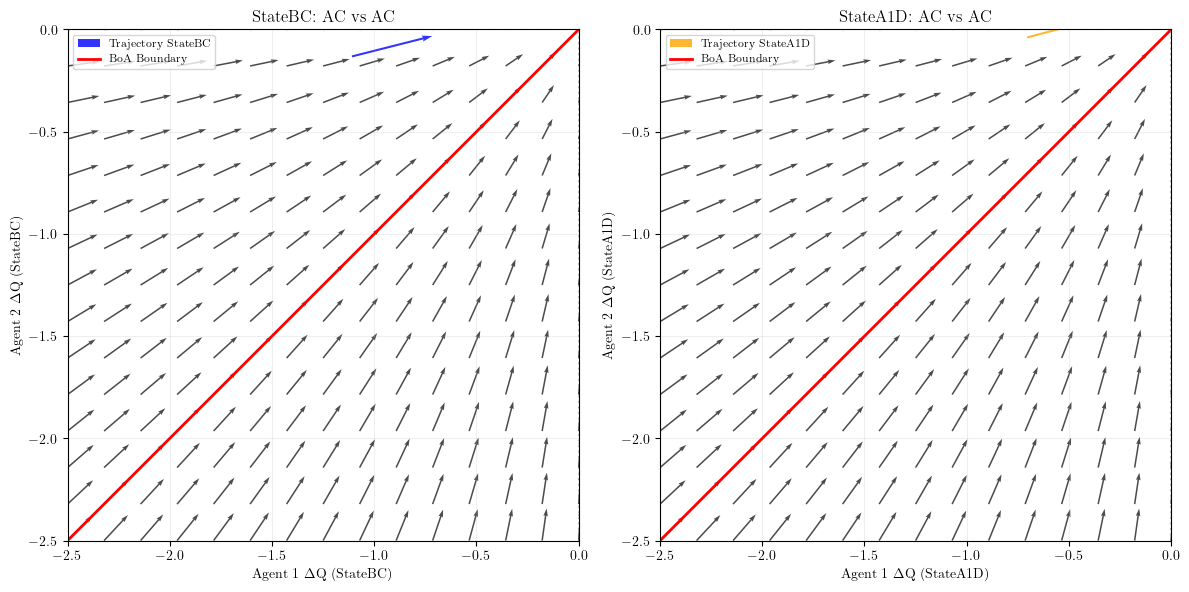

In [4]:
# Strategy pairs
strategy_pairs = [
    #("AD","AD"), ("AD","GT"), ("AD","AGT"), ("AD","AC"),
    #("GT","AD"), ("GT","GT"), ("GT","AGT"), ("GT","AC"),
    #("AGT","AD"), ("AGT","GT"), ("AGT","AGT"), ("AGT","AC"),
    #("AC","AD"), ("AC","GT"), ("AC","AGT"), 
    ("AC","AC")
]
stop_when_cross = True
# Map opponent strategy to function
func_map = {
    "AD": QvaluesADvsAD,
    "GT": QvaluesGTvsGT,
    "AGT": QvaluesADvsAGT,
    "AC": QvaluesADvsAC
}
randomseeds = np.random.randint(1, 1020131031, size=1)  # 5 is exclusive

for seed in randomseeds:
    np.random.seed(seed)
    print(f"Using seed: {seed}")
    for s1, s2 in strategy_pairs:
        print(f"Running pair: ({s1}, {s2})")

        # Initialize algorithm with fixed strategy pair
        algo = Algorithm(
            e=epsilon, lambda_val=0, alpha=alpha, delta=d,
            init_mode='fixed', tolerance=1e-10000, 
            M=50, strategy1=s1, strategy2=s2, verbose=False
        )

        # Run the algorithm
        q1_history_per_sample_algo, q2_history_per_sample_algo, batch_times_algo, timeout_out, timeout_vi = algo.run()

        # Pick a sample
        exp = np.random.randint(0, 50)
        q1 = convert_dict_to_mean_df(q1_history_per_sample_algo, mean=False)[exp]
        q2 = convert_dict_to_mean_df(q2_history_per_sample_algo, mean=False)[exp]
        if stop_when_cross:
            q1, q2 = trim_q_by_strategy(q1, q2, s1, s2)
        func1 = func_map[s2]  # x-component uses opponent strategy s2
        func2 = func_map[s1]  # y-component uses same opponent strategy
        #check if the ordering changes here input (q1, q2, s1, s2)
        # Plot vector field with strategy information
        plotter = VectorFieldAutomatic(
            q1=q1, q2=q2,
            t=t, r=r, p=p, s=s, epsilon=epsilon, d=d,
            func1=func1,
            func2=func2,
            strategy1=s1,    # Add strategy1
            strategy2=s2,    # Add strategy2
            alpha=alpha,
            density=15,
            show_trajectory=True,
            show_basin=True
        )
        
                    
                    
        plotter.plot(show_all_quadrants=False)
        
    





In [5]:
#ORGANIZE THE DESCRIPTION:
#BBoA = BoundaryBasinOfAttraction
#first you plot ADAD and then GTGT #equilibria
#plot two side of bboa
#the case in which just the bboa decide in which equilibria we will go
#AD-GT: if you start below the bboa you will definetely go to GT, if you start on top of the bboa you will go to AD (top-right quadrant)
# target remains in the top right quadrant


#AD - AGT: we don't have the bboa, in any initialization will go to ADAD, there is nothing different can happen, mention ADAD plot.
#AD - AC: the only place top boundary but there are
# two options (which axes we cross first in A1D state or BC state): A1D first) so agent2 is switching from cooperating to defecting in the A1D state, 
# but it still cooperating in the BC state, so agent 2 is switching to play GT, and player1 is still playing AD, so we need to look at AD-GT case,
# so now the moment in which cross the axes on the left hand side determines looking at the point on the right hand side whether you go to AD or GT.
#2 option) we are crossing first in the BC state, so we go to AD-AGT, and we definetely go to ADAD as discussed above

#AC-AC: 
#cross A1D (right of the boundary): 
#cross BC  (right of the boundary):
#cross A1D (left of the boundary ):
#cross BC  (left of the boundary first): cross on the right hadn boundary, they will end up in AGT-AC, we come into this plot from the left
# ACAC can lead to AGT-AC, GT-AC, AC-AGT, AC-GT, and from those situation where can I go?




In [6]:
import numpy as np

def target_dQ(func1, func2, idx, params):
    t, r, p, s, epsilon, delta = params
    Q1 = func1(t, r, p, s, epsilon, delta)[idx]
    Q2 = func2(t, r, p, s, epsilon, delta)[idx]
    dQx = Q1[0] - Q1[1]
    dQy = Q2[0] - Q2[1]
    return dQx, dQy


In [7]:
def boa_probability(func1, func2, idx, params):
    dQx, dQy = target_dQ(func1, func2, idx, params)

    # No BBoA
    if dQx * dQy <= 0:
        return None

    m = abs(dQy / dQx)
    P_small = 0.5 * min(m, 1/m)
    return P_small


In [8]:
params = (1, 0.8, 0.2, 0, 0.1, 0.6)

cases = {
    "AD-AD": {"type": "trivial", "P_GT": 0},
    "GT-GT": {"type": "trivial", "P_GT": 1},

    "AD-GT": {"type": "boa",
              "funcs": (QvaluesADvsAD, QvaluesGTvsGT)},
    "GT-AD": {"type": "boa",
              "funcs": (QvaluesGTvsGT, QvaluesADvsAD)},

    "AD-AGT": {"type": "trivial", "P_GT": 0},
    "AGT-AD": {"type": "trivial", "P_GT": 0},

    "AD-AC": {"type": "cross", "branch": "AD-GT"},
    "AC-AD": {"type": "cross", "branch": "AD-GT"},

    "AC-AC": {"type": "cross", "branch": "AD-GT", "weight": 0.5},

    "GT-AC": {"type": "boa",
              "funcs": (QvaluesGTvsGT, QvaluesADvsAC)},
    "AC-GT": {"type": "boa",
              "funcs": (QvaluesADvsAC, QvaluesGTvsGT)},
}


In [9]:
results = {}

for name, info in cases.items():
    case_type = info["type"]

    if case_type == "trivial":
        results[name] = info.get("P_GT", 0.0)

    elif case_type == "boa":
        funcs = info["funcs"]
        func1, func2 = funcs
        
        # Compute boa_probability for both states (StateC and StateD)
        # We need to check both states because the BBoA might exist in one but not the other
        probs_state0 = None
        probs_state1 = None
        dQx0, dQy0 = None, None
        dQx1, dQy1 = None, None
        
        for idx in [0, 1]:  # StateC (idx=0) and StateD (idx=1)
            prob = boa_probability(func1, func2, idx, params)
            dQx, dQy = target_dQ(func1, func2, idx, params)
            
            if idx == 0:
                probs_state0 = prob
                dQx0, dQy0 = dQx, dQy
            else:
                probs_state1 = prob
                dQx1, dQy1 = dQx, dQy
        
        # Determine which state to use (prefer StateC if both have BBoA, otherwise use the one with BBoA)
        prob_to_use = None
        dQx_use, dQy_use = None, None
        
        if probs_state0 is not None:
            prob_to_use = probs_state0
            dQx_use, dQy_use = dQx0, dQy0
        elif probs_state1 is not None:
            prob_to_use = probs_state1
            dQx_use, dQy_use = dQx1, dQy1
        
        if prob_to_use is None:
            # No valid BBoA in either state - this shouldn't happen for "boa" type
            # But if it does, we can't compute probability
            results[name] = None
        else:
            # Determine which equilibrium is in the small basin
            # The formula P_small = 0.5 * min(m, 1/m) gives probability of smaller basin
            # We need to determine if GT-GT is in the small or large basin
            
            # The ratio m = |dQy/dQx| determines relative basin sizes
            # The BBoA is a line through origin with direction (-dx, -dy)
            # The area of each basin is proportional to the angle subtended
            
            m = abs(dQy_use / dQx_use) if abs(dQx_use) > 1e-10 else 1.0
            
            # Determine which equilibrium corresponds to which basin based on the case
            # For AD-GT: func1=ADvsAD (target AD-AD, x-direction), func2=GTvsGT (target GT-GT, y-direction)
            # According to comments: below BBoA → GT-GT, above BBoA → AD-AD
            # The basin sizes depend on the angle: if m < 1, the y-basin (GT-GT) is smaller
            
            if "AD-GT" in name or "GT-AD" in name:
                # For AD-GT: func1 points to AD-AD (x), func2 points to GT-GT (y)
                # If m < 1: y-basin (GT-GT) is smaller → P_GT = P_small
                # If m > 1: x-basin (AD-AD) is smaller → P_GT = 1 - P_small
                if m < 1.0:
                    results[name] = prob_to_use
                else:
                    results[name] = 1.0 - prob_to_use
                    
            elif "GT-AC" in name or "AC-GT" in name:
                # For GT-AC: func1=GTvsGT (target GT-GT), func2=ADvsAC (target AD-AC → AD-AD)
                # The logic is similar but we need to check the signs to determine orientation
                # Both dx and dy should be positive (top-right quadrant) for this case
                # If m < 1: the basin in y-direction (AD-AD via func2) is smaller
                # If m > 1: the basin in x-direction (GT-GT via func1) is smaller
                
                # Check signs to understand geometry
                if dQx_use > 0 and dQy_use > 0:
                    # Both positive: GT-GT is in x-direction, AD-AD is in y-direction
                    if m < 1.0:
                        # y-basin (AD-AD) is smaller, so P_GT = 1 - P_small
                        results[name] = 1.0 - prob_to_use
                    else:
                        # x-basin (GT-GT) is smaller, so P_GT = P_small
                        results[name] = prob_to_use
                else:
                    # Fallback: use similar logic as AD-GT
                    if m < 1.0:
                        results[name] = prob_to_use
                    else:
                        results[name] = 1.0 - prob_to_use
            else:
                # Unknown case, use the probability as-is
                results[name] = prob_to_use
            
            # Ensure probability is in [0,1]
            results[name] = max(0.0, min(1.0, results[name]))

    elif case_type == "cross":
        # For "cross" cases, there's no BBoA - we need to determine which axis is crossed first
        # According to comments: AD-AC can cross A1D first (→ AD-GT) or BC first (→ AD-AGT → ADAD)
        # For now, we use the branch probability with a weight
        base = info["branch"]
        weight = info.get("weight", 1.0)

        base_value = results.get(base) or 0.0  # safe fallback
        results[name] = weight * base_value

# Now compute totals safely - only use valid probabilities in [0,1]
valid_values = [v for v in results.values() if v is not None and 0 <= v <= 1]
if len(valid_values) > 0:
    P_GT_total = np.mean(valid_values)
    P_AD_total = 1 - P_GT_total
else:
    P_GT_total = 0.0
    P_AD_total = 1.0

# Print nicely
print("Case        | P_GT     | P_AD")
print("--------------------------------")
for k, v in results.items():
    if v is None:
        print(f"{k:12s} |    None  |    None")
    else:
        val = max(0.0, min(1.0, v))  # Clamp to [0,1]
        print(f"{k:12s} | {val:8.4f} | {1-val:8.4f}")

print("\nTotals (only valid probabilities):")
print(f"P_GT_total = {P_GT_total:.4f}, P_AD_total = {P_AD_total:.4f}")


Case        | P_GT     | P_AD
--------------------------------
AD-AD        |   0.0000 |   1.0000
GT-GT        |   1.0000 |   0.0000
AD-GT        |   0.4093 |   0.5907
GT-AD        |   0.5907 |   0.4093
AD-AGT       |   0.0000 |   1.0000
AGT-AD       |   0.0000 |   1.0000
AD-AC        |   0.4093 |   0.5907
AC-AD        |   0.4093 |   0.5907
AC-AC        |   0.2047 |   0.7953
GT-AC        |   0.4093 |   0.5907
AC-GT        |   0.5907 |   0.4093

Totals (only valid probabilities):
P_GT_total = 0.3658, P_AD_total = 0.6342


In [10]:
print("Initialization | P(GT-GT) | P(AD-AD)")
print("------------------------------------")
for k, v in results.items():
    print(f"{k:12s} | {v:8.4f} | {1-v:8.4f}")


Initialization | P(GT-GT) | P(AD-AD)
------------------------------------
AD-AD        |   0.0000 |   1.0000
GT-GT        |   1.0000 |   0.0000
AD-GT        |   0.4093 |   0.5907
GT-AD        |   0.5907 |   0.4093
AD-AGT       |   0.0000 |   1.0000
AGT-AD       |   0.0000 |   1.0000
AD-AC        |   0.4093 |   0.5907
AC-AD        |   0.4093 |   0.5907
AC-AC        |   0.2047 |   0.7953
GT-AC        |   0.4093 |   0.5907
AC-GT        |   0.5907 |   0.4093


In [11]:
P_GT_total = np.mean(list(results.values()))
P_AD_total = 1 - P_GT_total

P_GT_total, P_AD_total


(np.float64(0.3657505285412262), np.float64(0.6342494714587739))